In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib import font_manager
from pathlib import Path
import rasterio as rio
import numpy as np
from socket import gethostname
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

host = gethostname()

if host == 'gcer-a100':
    font_path = '/home/dhester/.fonts/InterVariable.ttf'
elif host == 'ABE-BC546S3':
    font_path = r"C:\Users\dh2306\AppData\Local\Microsoft\Windows\Fonts\Inter-VariableFont_opsz,wght.ttf"
elif host == 'MacBookPro':
    font_path = '/Users/dak/Library/Fonts/Inter-VariableFont_opsz,wght.ttf'
else:
    raise NotImplementedError("Unknown host. Please set the Inter font path for this machine.")

font_manager.fontManager.addfont(font_path)
prop = font_manager.FontProperties(fname=font_path)

# plt.style.use('bmh')
plt.style.use('seaborn-v0_8-colorblind')
# plt.style.use('fivethirtyeight')
# set grid background color to white
# plt.rcParams['axes.facecolor'] = 'white'
# use outline around axes for better visibility when multiple axes are present
# plt.rcParams['axes.edgecolor'] = 'black'
# plt.rcParams['axes.linewidth'] = 0.5


plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()
# plt.rcParams["text.usetex"] = False
plt.rcParams.update({
    'mathtext.fontset': 'stix',
    'mathtext.default': 'it',
})


In [2]:
sample_path_roots = {
    "pred_regression": Path("/home/dhester/s2flow/runs/s2flow_sr_eval_regression/sr_outputs"),
    "pred_euler": Path('/home/dhester/s2flow/runs/s2flow_sr_eval_steps/s2flow_sr_eval_euler_1/sr_outputs/'),
    "pred_realesrgan": Path('/home/dhester/s2flow/runs/s2flow_realesrgan/sr_outputs/'),
    "pred_lanczos": Path('/home/dhester/s2flow/data/s2flow-s2naip/sentinel2/'),
    "true": Path('/home/dhester/s2flow/data/s2flow-s2naip/naip/')
}

sample_ids = [file.stem for file in sample_path_roots["pred_regression"].glob('*.tif')]

In [3]:
def get_pixel_df(sample_id: str) -> pd.DataFrame:
    
    preds = {}
    paths = {}
    for pred_type, pred_path_root in sample_path_roots.items():
        paths[f"path_{pred_type}"] = str(pred_path_root / f"{sample_id}.tif")
        with rio.open(pred_path_root / f"{sample_id}.tif", "r") as f:
            preds[pred_type] = f.read()
 
    sample_shape = preds["true"].shape

    sample_data_dict = {
        'sample_id': sample_id,
        "pixel_row": np.repeat(np.arange(sample_shape[1]), sample_shape[2]),
        "pixel_col": np.tile(np.arange(sample_shape[2]), sample_shape[1]),
    }
    sample_data_dict.update(paths)
    
    for band_idx, band_name in enumerate(['red', 'green', 'blue', 'nir']):
        for pred_type, pred_arr in preds.items():
            sample_data_dict[f"{band_name}_{pred_type}"] = pred_arr[band_idx].ravel()
    
    df = pd.DataFrame(sample_data_dict)
    return df

pixel_values_par_path = Path("/home/dhester/s2flow/logs/inference_pixel_values.par")

if pixel_values_par_path.exists():
    all_pixel_df = pd.read_parquet(pixel_values_par_path)
    print(f"Loaded pixel values from {pixel_values_par_path}, shape: {all_pixel_df.shape}")
else:
    all_pixel_dfs = Parallel(n_jobs=-1)(
        delayed(get_pixel_df)(sample_id) for sample_id in tqdm(sample_ids)
    )

    all_pixel_df = pd.concat(all_pixel_dfs, ignore_index=True)
    print(f"Saving pixel values to {pixel_values_par_path}, shape: {all_pixel_df.shape}")
    all_pixel_df.to_parquet("/home/dhester/s2flow/logs/inference_pixel_values.par")

Loaded pixel values from /home/dhester/s2flow/logs/inference_pixel_values.par, shape: (394264576, 28)


In [ ]:
def mape(y_true, y_pred):
    ape = np.abs((y_true - y_pred) / y_true)
    ape_no_infs = ape[np.isfinite(ape)]
    return np.mean(ape_no_infs)

def get_regression_line(y_true, y_pred):
    return np.polyfit(y_true, y_pred, 1)

def get_metrics(y_true, y_pred, pred_type: str, band_name: str, scale: float = 1.0/10000.0,):
    
    y_true = y_true * scale
    y_pred = y_pred * scale

    # compute all 4 metrics in parallel
    metrics = Parallel(n_jobs=-1)(
        delayed(lambda metric_func: metric_func(y_true, y_pred))(
            func
        ) for func in [
            r2_score,
            root_mean_squared_error,
            mean_absolute_error,
            mape,
            get_regression_line,
        ]
    )
    metrics = {
        "pred_type": pred_type,
        "band_name": band_name,
        "r2": metrics[0],
        "rmse": metrics[1],
        "mae": metrics[2],
        "mape": metrics[3],
        "ols_w": metrics[4][0],
        "ols_b": metrics[4][1]
    }
    return metrics

metrics_path = Path("../logs/pixelwise_metrics.csv")

if metrics_path.exists():
    metrics_df = pd.read_csv(metrics_path)
    print(f"Loaded metrics from {metrics_path}, shape: {metrics_df.shape}")
else:
    metrics_dicts = Parallel(n_jobs=4)(
        delayed(get_metrics)(
            all_pixel_df[f"{band_name}_true"], 
            all_pixel_df[f"{band_name}_{pred_type}"],
            pred_type=pred_type,
            band_name=band_name
        )
        for band_name in ["red", "green", "blue", "nir"]
        for pred_type in [pred_type for pred_type in sample_path_roots.keys() if pred_type != "true"]
    )

    metrics_df = pd.DataFrame(metrics_dicts)
    print(f"Saving metrics to {metrics_path}, shape: {metrics_df.shape}")
    metrics_df.to_csv("../logs/pixelwise_metrics.csv", index=False)


Loaded metrics from ../logs/pixelwise_metrics.csv, shape: (16, 8)


In [5]:
# for plotting, use a random subset that way we don't overwhelm matplotlib
n_plot_points_per_sample = 1
all_pixel_subsample_df = all_pixel_df.groupby("sample_id").sample(n=n_plot_points_per_sample, random_state=1701)
# all_pixel_subsample_df = all_pixel_df.sample(n=10000, random_state=1701)
print(f"Plotting {len(all_pixel_subsample_df)} points")

Plotting 6016 points


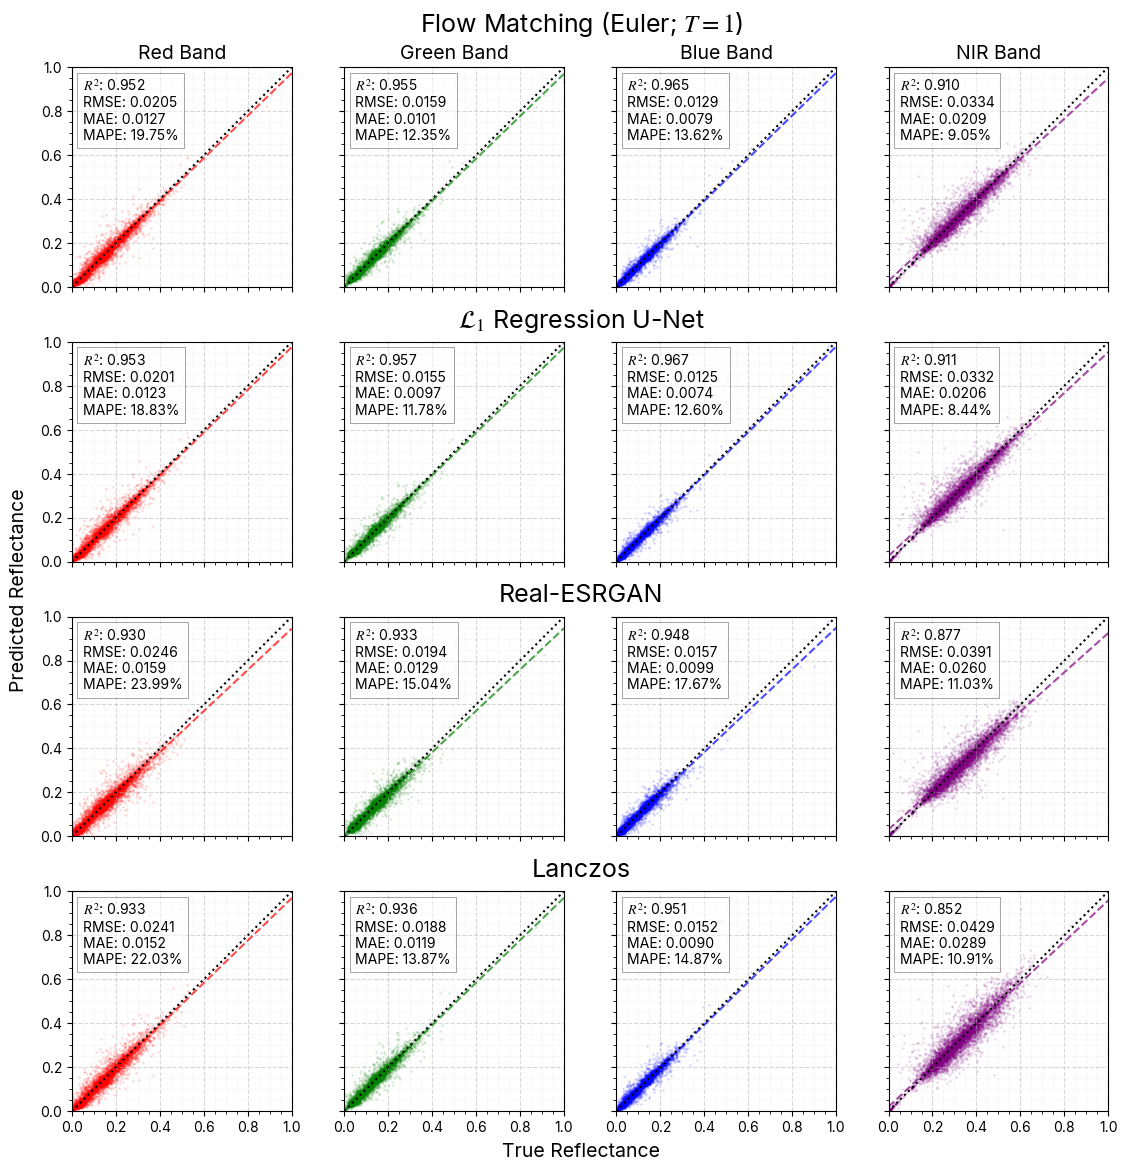

In [6]:
color_dict = {
    'red': 'red',
    'green': 'green',
    'blue': 'blue',
    'nir': 'purple',
}
band_titles = {
    'red': 'Red Band',
    'green': 'Green Band',
    'blue': 'Blue Band',
    'nir': 'NIR Band',
}
model_titles = {
    'pred_euler': 'Euler Model',
    'pred_regression': '$L_1$ Regression',
    'pred_realesrgan': 'Real-ESRGAN Model',
    'pred_lanczos': 'Lanczos Model',
}


size = 2.8
fig, ax = plt.subplots(4, 4, figsize=(4*size, 4*size), sharex="col", sharey="row")

for i, pred_type in enumerate([pred_type for pred_type in model_titles.keys() if pred_type != "true"]):
    for j, band_name in enumerate(band_titles.keys()):
        
        # enable gridlines first
        ax[i, j].grid(True, linestyle='--', alpha=0.5)
        # set minor gridlines
        ax[i, j].minorticks_on()
        ax[i, j].grid(True, which='minor', linestyle='--', alpha=0.1)
        
        ax[i, j].scatter(
            all_pixel_subsample_df[f"{band_name}_true"] / 10000, 
            all_pixel_subsample_df[f"{band_name}_{pred_type}"] / 10000, 
            s=1,
            alpha=0.1,
            color=color_dict[band_name],
            rasterized=True
        )
        
        # plot the regression line
        model_metrics = metrics_df.loc[
            (metrics_df["pred_type"] == pred_type) &
            (metrics_df["band_name"] == band_name)
        ].iloc[0]
        
        w, b = model_metrics["ols_w"], model_metrics["ols_b"]
        x_vals = np.array([0, 1])
        y_vals = w * x_vals + b
        ax[i, j].plot(x_vals, y_vals, color=color_dict[band_name], linestyle='--', alpha=0.7)
        ax[i, j].plot([0, 1], [0, 1], color='k', linestyle='dotted') # 1:1 line
        
        # add statistics to upper left
        ax[i, j].text(
            0.05, 0.95, 
            # f'{pred_type} - {band_name}\n' +
            f'$R^2$: {model_metrics["r2"]:.3f}\n' + 
            f'RMSE: {model_metrics["rmse"]:.4f}\n' + 
            f'MAE: {model_metrics["mae"]:.4f}\n' + 
            f'MAPE: {model_metrics["mape"]:.2%}',
            transform=ax[i, j].transAxes, 
            fontsize=10,
            ha='left', 
            va='top', 
            bbox=dict(facecolor='white', alpha=0.5, linewidth=0.5)
        )
        
        # set to 0, 1 for both axes
        ax[i, j].set_xlim(0, 1)
        ax[i, j].set_ylim(0, 1)
        ax[i, j].set_aspect('equal', 'box')
        
        # don't use axis labels
        ax[i, j].set_xlabel("")
        ax[i, j].set_ylabel("")
        
        # set band titles
        if i == 0:
            ax[i, j].set_title(band_titles[band_name], fontsize=14)

fig.tight_layout()

axis_fontsize = 14
fig.supxlabel('True Reflectance', fontsize=axis_fontsize, y=-0.01)
fig.supylabel('Predicted Reflectance', fontsize=axis_fontsize, x=-0.01)

model_fontsize = 18
fig.text(0.5, 1.005, 'Flow Matching (Euler; $T=1$)', va='center', ha='center', fontsize=model_fontsize)
fig.subplots_adjust(hspace=.25)
fig.text(0.5, .74, r'$\mathcal{L}_1$ Regression U-Net', va='center', ha='center', fontsize=model_fontsize)
fig.text(0.5, .495, 'Real-ESRGAN', va='center', ha='center', fontsize=model_fontsize)
fig.text(0.5, .25, 'Lanczos', va='center', ha='center', fontsize=model_fontsize)

out_dir = Path('../figures/sampling_regression3/')
out_dir.mkdir(parents=True, exist_ok=True)
metrics_df.to_csv(out_dir / 'metrics.csv', index=False)
for filetype in ['png', 'pdf']:
    fig.savefig(out_dir / f'sampling_regression_comparison.{filetype}', dpi=300, bbox_inches='tight')

plt.show()